In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

In [1]:
!pip install huggingface_hub
from huggingface_hub import login
import shutil

from huggingface_hub import snapshot_download

HF_TOKEN = os.environ.get("HF_TOKEN")

if HF_TOKEN:
    login(token=HF_TOKEN)
path = snapshot_download(
    repo_id="ibrahimhamamci/DENTEX",
    repo_type="dataset"
)

print(path)

print("DENTEX ready")

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

/root/.cache/huggingface/hub/datasets--ibrahimhamamci--DENTEX/snapshots/7b27ccc8e342dcb774f69adc6ca5e6c09fefce93
DENTEX ready


In [2]:
import zipfile
import os

base_path = "/root/.cache/huggingface/hub/datasets--ibrahimhamamci--DENTEX/snapshots/7b27ccc8e342dcb774f69adc6ca5e6c09fefce93/DENTEX"

for file in ["training_data.zip", "validation_data.zip", "test_data.zip"]:
    zip_path = os.path.join(base_path, file)
    extract_path = os.path.join(base_path, file.replace(".zip", ""))

    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_path)

    print(f"Extracted {file}")

Extracted training_data.zip
Extracted validation_data.zip
Extracted test_data.zip


In [4]:
import json
import os
import shutil
import cv2
import random
from collections import defaultdict

random.seed(42)

# ====================== PATHS ======================
base = "/root/.cache/huggingface/hub/datasets--ibrahimhamamci--DENTEX/snapshots/7b27ccc8e342dcb774f69adc6ca5e6c09fefce93/DENTEX"
root = "/kaggle/working/dentex"

for folder in ["images/train", "images/val", "images/test", "labels/train", "labels/val", "labels/test"]:
    os.makedirs(f"{root}/{folder}", exist_ok=True)

datasets = [
    {
        "json": f"{base}/training_data/training_data/quadrant_enumeration/train_quadrant_enumeration.json",
        "img_dir": f"{base}/training_data/training_data/quadrant_enumeration/xrays",
        "prefix": ""
    },
    {
        "json": f"{base}/training_data/training_data/quadrant-enumeration-disease/train_quadrant_enumeration_disease.json",
        "img_dir": f"{base}/training_data/training_data/quadrant-enumeration-disease/xrays",
        "prefix": "d_"
    }
]

# ====================== PROCESS + MERGE ======================
print("Processing and merging data...")

for ds in datasets:
    with open(ds["json"]) as f:
        data = json.load(f)
    
    id_to_name = {img["id"]: ds["prefix"] + img["file_name"] for img in data["images"]}
    img_anns = {}
    for ann in data["annotations"]:
        img_anns.setdefault(ann["image_id"], []).append(ann)

    for img_id, anns in img_anns.items():
        new_name = id_to_name[img_id]
        old_name = new_name.replace(ds["prefix"], "")
        src = os.path.join(ds["img_dir"], old_name)
        if not os.path.exists(src):
            continue

        shutil.copy(src, f"{root}/images/train/{new_name}")

        img = cv2.imread(src)
        h, w = img.shape[:2]
        label_path = f"{root}/labels/train/{new_name.replace('.png', '.txt')}"
        
        lines = []
        for ann in anns:
            q = ann.get("category_id_1")
            t = ann.get("category_id_2")
            if q is None or t is None: continue
            cls = q * 8 + t - 1 if (q * 8 + t) > 0 else 0
            
            x, y, bw, bh = ann["bbox"]
            xc = (x + bw/2) / w
            yc = (y + bh/2) / h
            lines.append(f"{cls} {xc:.6f} {yc:.6f} {bw/w:.6f} {bh/h:.6f}")
        
        if lines:
            with open(label_path, "w") as f:
                f.write("\n".join(lines))

print("Merging & Preprocessing completed!")

Processing and merging data...
Merging & Preprocessing completed!


In [5]:
# ====================== SPLITTING ======================
print("Creating Train/Val/Test split...")

image_to_classes = defaultdict(set)
for txt_file in os.listdir(f"{root}/labels/train"):
    if not txt_file.endswith(".txt"): continue
    img_name = txt_file.replace(".txt", ".png")
    with open(f"{root}/labels/train/{txt_file}") as f:
        for line in f:
            if line.strip():
                cls = int(line.split()[0])
                image_to_classes[img_name].add(cls)

all_images = list(image_to_classes.keys())
random.shuffle(all_images)

total = len(all_images)
train_size = int(total * 0.80)
val_size = int(total * 0.15)

train_imgs = all_images[:train_size]
val_imgs = all_images[train_size:train_size + val_size]
test_imgs = all_images[train_size + val_size:]

def move_files(img_list, split):
    for name in img_list:
        shutil.move(f"{root}/images/train/{name}", f"{root}/images/{split}/{name}")
        txt_name = name.replace(".png", ".txt")
        shutil.move(f"{root}/labels/train/{txt_name}", f"{root}/labels/{split}/{txt_name}")

move_files(val_imgs, "val")
move_files(test_imgs, "test")

print(f"Split → Train: {len(train_imgs)} | Val: {len(val_imgs)} | Test: {len(test_imgs)}")

# ====================== YAML ======================
with open("dentex_v2.yaml", "w") as f:
    f.write("""path: /kaggle/working/dentex
train: images/train
val: images/val
test: images/test

nc: 32
names:
  0: "11"
  1: "12"
  2: "13"
  3: "14"
  4: "15"
  5: "16"
  6: "17"
  7: "18"
  8: "21"
  9: "22"
  10: "23"
  11: "24"
  12: "25"
  13: "26"
  14: "27"
  15: "28"
  16: "31"
  17: "32"
  18: "33"
  19: "34"
  20: "35"
  21: "36"
  22: "37"
  23: "38"
  24: "41"
  25: "42"
  26: "43"
  27: "44"
  28: "45"
  29: "46"
  30: "47"
  31: "48"
""")

print("dentex_v2.yaml created!")

Creating Train/Val/Test split...
Split → Train: 1049 | Val: 196 | Test: 67
dentex_v2.yaml created!


## Extended Progressive Training - YOLOv8m (5 Stages)

In [6]:
from ultralytics import YOLO

print("=== Extended Progressive Training - YOLOv8m (5 Stages) ===\n")

# Stage 1
print("Stage 1: 20 epochs")
model = YOLO("yolov8m.pt")
model.train(
    data="dentex_v2.yaml",
    epochs=20,
    imgsz=800,
    batch=8,
    name="progressive_stage1_8mm",
    seed=42,
    device=0,
    patience=0,
    amp=True
)

# Stage 2
print("\nStage 2: Resume + 20 epochs")
model2 = YOLO("runs/detect/progressive_stage1_8mm/weights/best.pt")
model2.train(
    data="dentex_v2.yaml",
    epochs=20,
    imgsz=800,
    batch=8,
    name="progressive_stage2_8mm",
    seed=42,
    device=0,
    patience=0,
    amp=True
)

# Stage 3
print("\nStage 3: Resume + 20 epochs")
model3 = YOLO("runs/detect/progressive_stage2_8mm/weights/best.pt")
model3.train(
    data="dentex_v2.yaml",
    epochs=20,
    imgsz=800,
    batch=8,
    name="progressive_stage3_8mm",
    seed=42,
    device=0,
    patience=0,
    amp=True
)

# Stage 4
print("\nStage 4: Resume + 20 epochs")
model4 = YOLO("runs/detect/progressive_stage3_8mm/weights/best.pt")
model4.train(
    data="dentex_v2.yaml",
    epochs=20,
    imgsz=800,
    batch=8,
    name="progressive_stage4_8mm",
    seed=42,
    device=0,
    patience=0,
    amp=True
)

# Stage 5
print("\nStage 5: Resume + 20 epochs (Final)")
model5 = YOLO("runs/detect/progressive_stage4_8mm/weights/best.pt")
model5.train(
    data="dentex_v2.yaml",
    epochs=20,
    imgsz=800,
    batch=8,
    name="progressive_stage5_final_8mm",
    seed=42,
    device=0,
    patience=0,
    amp=True
)

print("\n✅ Extended Progressive Training Completed! (Total 100 epochs)")

=== Extended Progressive Training - YOLOv8m (5 Stages) ===

Stage 1: 20 epochs
Ultralytics 8.4.46 🚀 Python-3.12.12 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=dentex_v2.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=800, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8m.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=progressive_stage1_8mm-2, nbs=64, nms=Fals

# paper


In [5]:
# ════════════════════════════════════════════════════════
# CELL 1 — Install
# ════════════════════════════════════════════════════════
!pip install ultralytics -q


# ════════════════════════════════════════════════════════
# CELL 2 — Imports
# ════════════════════════════════════════════════════════
import json, os, shutil, cv2, random, glob
from ultralytics import YOLO


# ════════════════════════════════════════════════════════
# CELL 3 — Convert COCO → YOLO (first dataset only)
# ════════════════════════════════════════════════════════
JSON_PATH = "/root/.cache/huggingface/hub/datasets--ibrahimhamamci--DENTEX/snapshots/7b27ccc8e342dcb774f69adc6ca5e6c09fefce93/DENTEX/training_data/training_data/quadrant_enumeration/train_quadrant_enumeration.json"
IMG_DIR   = "/root/.cache/huggingface/hub/datasets--ibrahimhamamci--DENTEX/snapshots/7b27ccc8e342dcb774f69adc6ca5e6c09fefce93/DENTEX/training_data/training_data/quadrant_enumeration/xrays"

staging_imgs   = "/kaggle/working/panorai_staging/images"
staging_labels = "/kaggle/working/panorai_staging/labels"
os.makedirs(staging_imgs,   exist_ok=True)
os.makedirs(staging_labels, exist_ok=True)

with open(JSON_PATH) as f:
    data = json.load(f)

id_to_name = {img["id"]: img["file_name"] for img in data["images"]}

img_anns = {}
for ann in data["annotations"]:
    img_anns.setdefault(ann["image_id"], []).append(ann)

skipped = 0
for img_id, anns in img_anns.items():
    img_name = id_to_name[img_id]
    src_img  = os.path.join(IMG_DIR, img_name)

    if not os.path.exists(src_img):
        skipped += 1
        continue

    shutil.copy(src_img, os.path.join(staging_imgs, img_name))

    img = cv2.imread(src_img)
    img_h, img_w = img.shape[:2]

    lines = []
    for ann in anns:
        cls = ann["category_id_1"] * 8 + ann["category_id_2"]
        x, y, w, h = ann["bbox"]
        xc = (x + w / 2) / img_w
        yc = (y + h / 2) / img_h
        w /= img_w
        h /= img_h
        lines.append(f"{cls} {xc} {yc} {w} {h}")

    stem = os.path.splitext(img_name)[0]
    with open(os.path.join(staging_labels, stem + ".txt"), "w") as f:
        f.write("\n".join(lines))

print(f"Total images converted : {len(os.listdir(staging_imgs))}")
print(f"Total label files      : {len(os.listdir(staging_labels))}")
print(f"Skipped                : {skipped}")


# ════════════════════════════════════════════════════════
# CELL 4 — Split 80 / 12 / 8  (exactly as the paper)
# ════════════════════════════════════════════════════════
for split in ["train", "val", "test"]:
    os.makedirs(f"/kaggle/working/panorai_dataset/images/{split}", exist_ok=True)
    os.makedirs(f"/kaggle/working/panorai_dataset/labels/{split}", exist_ok=True)

all_images = sorted(glob.glob(f"{staging_imgs}/*.png"))
random.seed(42)
random.shuffle(all_images)

n       = len(all_images)
n_train = int(n * 0.80)
n_val   = int(n * 0.12)

splits = {
    "train": all_images[:n_train],
    "val"  : all_images[n_train : n_train + n_val],
    "test" : all_images[n_train + n_val :],
}

for split, paths in splits.items():
    for img_path in paths:
        fname = os.path.basename(img_path)
        stem  = os.path.splitext(fname)[0]
        shutil.copy(img_path,
                    f"/kaggle/working/panorai_dataset/images/{split}/{fname}")
        shutil.copy(f"{staging_labels}/{stem}.txt",
                    f"/kaggle/working/panorai_dataset/labels/{split}/{stem}.txt")

for split in ["train", "val", "test"]:
    n_imgs = len(os.listdir(f"/kaggle/working/panorai_dataset/images/{split}"))
    n_lbls = len(os.listdir(f"/kaggle/working/panorai_dataset/labels/{split}"))
    print(f"{split:6s} → images: {n_imgs}  labels: {n_lbls}")


# ════════════════════════════════════════════════════════
# CELL 5 — Write YAML
# ════════════════════════════════════════════════════════
with open("panorai.yaml", "w") as f:
    f.write("""
path: /kaggle/working/panorai_dataset
train: images/train
val: images/val
test: images/test
names:
  0: "11"
  1: "12"
  2: "13"
  3: "14"
  4: "15"
  5: "16"
  6: "17"
  7: "18"
  8: "21"
  9: "22"
  10: "23"
  11: "24"
  12: "25"
  13: "26"
  14: "27"
  15: "28"
  16: "31"
  17: "32"
  18: "33"
  19: "34"
  20: "35"
  21: "36"
  22: "37"
  23: "38"
  24: "41"
  25: "42"
  26: "43"
  27: "44"
  28: "45"
  29: "46"
  30: "47"
  31: "48"
""")
print("panorai.yaml written.")


# ════════════════════════════════════════════════════════
# CELL 6 — Progressive Training  (3 × 10 epochs)
# ════════════════════════════════════════════════════════
TRAIN_CFG = dict(
    data     = "panorai.yaml",
    epochs   = 10,
    imgsz    = 640,
    batch    = 16,
    device   = 0,
    lr0      = 0.01,
    cos_lr   = True,
    patience = 20,
    hsv_h    = 0.0,
    hsv_s    = 0.0,
    flipud   = 0.0,
)

# Round 1 — from COCO pretrained weights
model = YOLO("yolo11m.pt")
model.train(**TRAIN_CFG, name="panorai_r1", project="/kaggle/working/panorai_runs")
best_r1 = "/kaggle/working/panorai_runs/panorai_r1/weights/best.pt"
print(f"Round 1 done → {best_r1}")

# Round 2 — from Round 1 best checkpoint
model = YOLO(best_r1)
model.train(**TRAIN_CFG, name="panorai_r2", project="/kaggle/working/panorai_runs")
best_r2 = "/kaggle/working/panorai_runs/panorai_r2/weights/best.pt"
print(f"Round 2 done → {best_r2}")

# Round 3 — from Round 2 best checkpoint
model = YOLO(best_r2)
model.train(**TRAIN_CFG, name="panorai_r3", project="/kaggle/working/panorai_runs")
best_r3 = "/kaggle/working/panorai_runs/panorai_r3/weights/best.pt"
print(f"Round 3 done → {best_r3}")


# ════════════════════════════════════════════════════════
# CELL 7 — Evaluate on the TEST SET
# ════════════════════════════════════════════════════════
print(f"\n{'Round':<35} {'mAP@.5':>8} {'mAP@.5:.95':>11} {'P':>8} {'R':>8}")
print("-" * 73)

for label, path in [
    ("Round 1 (10 ep)", best_r1),
    ("Round 2 (20 ep)", best_r2),
    ("Round 3 (30 ep)", best_r3),
]:
    m = YOLO(path).val(data="panorai.yaml", split="test", imgsz=640, device=0, verbose=False)
    print(f"{label:<35} {m.box.map50:>8.4f} {m.box.map:>11.4f} {m.box.mp:>8.4f} {m.box.mr:>8.4f}")

print("\nPaper targets (test set):")
print(f"{'Round 3 (paper)':<35} {'0.9128':>8} {'0.4974':>11} {'0.8241':>8} {'0.8670':>8}")

Total images converted : 634
Total label files      : 634
Skipped                : 0
train  → images: 507  labels: 507
val    → images: 76  labels: 76
test   → images: 51  labels: 51
panorai.yaml written.
Ultralytics 8.4.46 🚀 Python-3.12.12 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=panorai.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.0, hsv_s=0.0, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, 

─── Image 1: train_300.png
  Ground Truth  → 32 annotations : 11, 12, 13, 14, 15, 16, 17, 18, 21, 22, 23, 24, 25, 26, 27, 28, 31, 32, 33, 34, 35, 36, 37, 38, 41, 42, 43, 44, 45, 46, 47, 48
  Prediction    → 32 annotations : 33, 13, 28, 27, 31, 23, 37, 48, 38, 21, 18, 14, 24, 47, 46, 16, 36, 11, 43, 41, 22, 25, 35, 26, 45, 12, 32, 44, 17, 42, 34, 15

─── Image 2: train_184.png
  Ground Truth  → 27 annotations : 11, 12, 13, 14, 15, 16, 17, 21, 22, 23, 24, 25, 26, 27, 31, 32, 33, 34, 35, 36, 41, 42, 43, 44, 45, 46, 47
  Prediction    → 29 annotations : 27, 26, 36, 11, 24, 35, 16, 37, 45, 47, 32, 17, 13, 23, 25, 31, 41, 21, 34, 46, 44, 33, 15, 14, 22, 42, 12, 43, 14
  ⚠ Extra       : 37



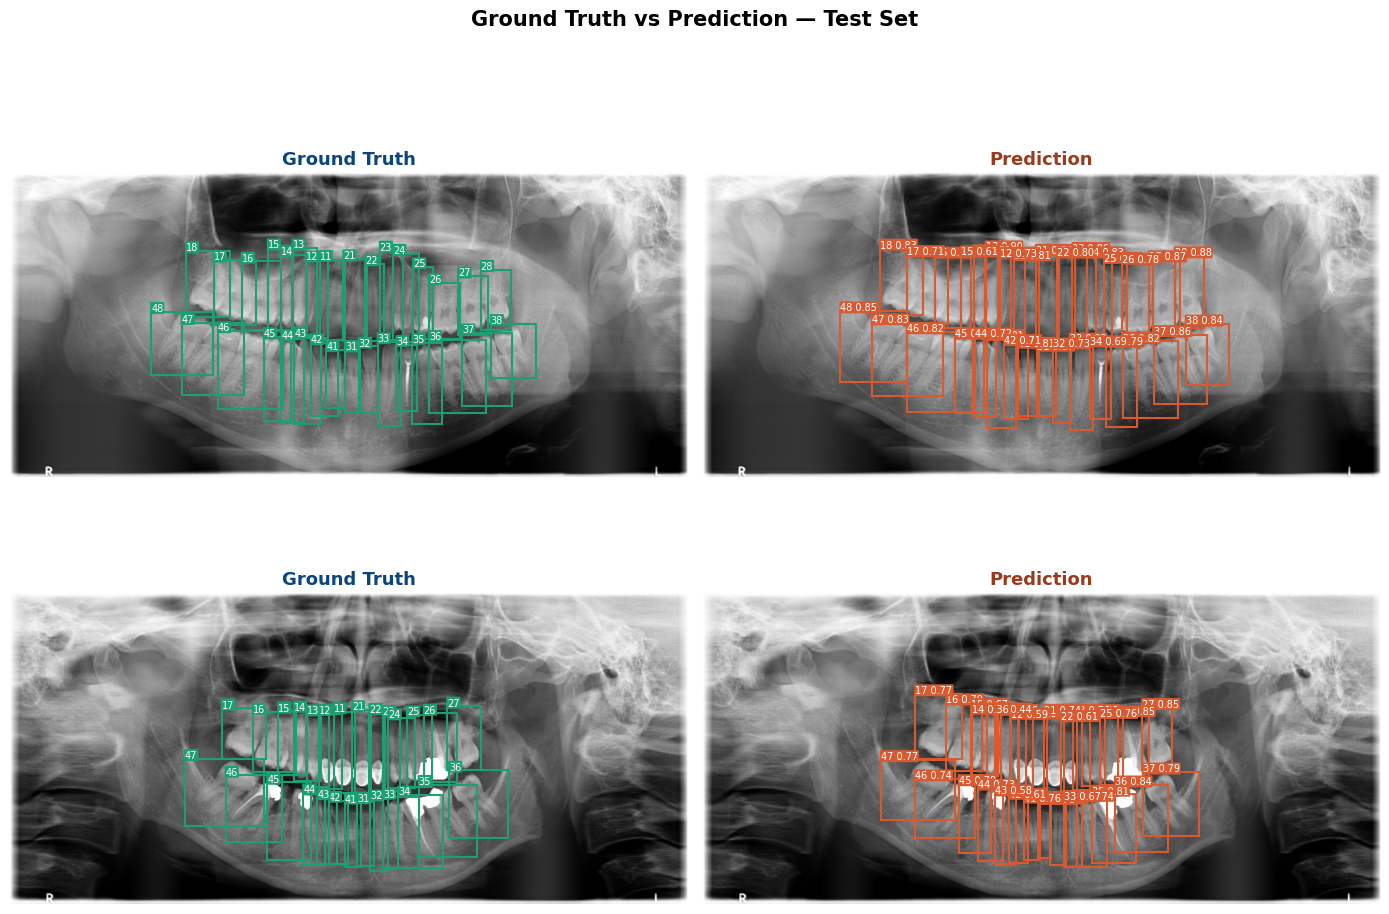

Saved → /kaggle/working/gt_vs_pred.png


In [8]:
import cv2, random, os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from ultralytics import YOLO

# ── config ──────────────────────────────────────────────
BEST_MODEL  = "/kaggle/working/panorai_runs/panorai_r2/weights/best.pt"
IMG_DIR     = "/kaggle/working/panorai_dataset/images/test"
LABEL_DIR   = "/kaggle/working/panorai_dataset/labels/test"
YAML_NAMES  = {i: str(v) for i, v in enumerate([
    "11","12","13","14","15","16","17","18",
    "21","22","23","24","25","26","27","28",
    "31","32","33","34","35","36","37","38",
    "41","42","43","44","45","46","47","48"
])}

# ── pick 2 random test images ────────────────────────────
all_imgs = sorted([f for f in os.listdir(IMG_DIR) if f.endswith(".png")])
random.seed(7)
chosen = random.sample(all_imgs, 2)

model = YOLO(BEST_MODEL)

def draw_gt(ax, img_bgr, label_path):
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    h, w = img_bgr.shape[:2]
    ax.imshow(img_rgb)
    ax.set_title("Ground Truth", fontsize=13, fontweight="bold", color="#0C447C")
    ax.axis("off")
    with open(label_path) as f:
        for line in f:
            parts = line.strip().split()
            cls, xc, yc, bw, bh = int(parts[0]), *map(float, parts[1:])
            x1 = (xc - bw / 2) * w
            y1 = (yc - bh / 2) * h
            rect = patches.Rectangle((x1, y1), bw * w, bh * h,
                                      linewidth=1.5, edgecolor="#1D9E75", facecolor="none")
            ax.add_patch(rect)
            ax.text(x1, y1 - 3, YAML_NAMES[cls],
                    fontsize=7, color="white",
                    bbox=dict(boxstyle="round,pad=0.1", facecolor="#1D9E75", edgecolor="none"))

def draw_pred(ax, img_bgr, results):
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    ax.imshow(img_rgb)
    ax.set_title("Prediction", fontsize=13, fontweight="bold", color="#993C1D")
    ax.axis("off")
    boxes = results[0].boxes
    for box in boxes:
        x1, y1, x2, y2 = box.xyxy[0].tolist()
        cls  = int(box.cls[0])
        conf = float(box.conf[0])
        rect = patches.Rectangle((x1, y1), x2 - x1, y2 - y1,
                                  linewidth=1.5, edgecolor="#D85A30", facecolor="none")
        ax.add_patch(rect)
        ax.text(x1, y1 - 3, f"{YAML_NAMES[cls]} {conf:.2f}",
                fontsize=7, color="white",
                bbox=dict(boxstyle="round,pad=0.1", facecolor="#D85A30", edgecolor="none"))

# ── plot ─────────────────────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle("Ground Truth vs Prediction — Test Set", fontsize=15, fontweight="bold", y=1.01)

for row, fname in enumerate(chosen):
    img_path   = os.path.join(IMG_DIR, fname)
    stem       = os.path.splitext(fname)[0]
    label_path = os.path.join(LABEL_DIR, stem + ".txt")

    img_bgr = cv2.imread(img_path)
    results = model.predict(img_path, imgsz=640, conf=0.25, verbose=False)

    draw_gt  (axes[row][0], img_bgr, label_path)
    draw_pred(axes[row][1], img_bgr, results)
    

for row, fname in enumerate(chosen):
    img_path   = os.path.join(IMG_DIR, fname)
    stem       = os.path.splitext(fname)[0]
    label_path = os.path.join(LABEL_DIR, stem + ".txt")

    # ground truth classes
    with open(label_path) as f:
        gt_classes = [YAML_NAMES[int(line.strip().split()[0])] for line in f]

    # predicted classes
    results    = model.predict(img_path, imgsz=640, conf=0.25,iou=0.6, verbose=False)
    pred_boxes = results[0].boxes
    pred_classes = [YAML_NAMES[int(b.cls[0])] for b in pred_boxes]

    print(f"─── Image {row+1}: {fname}")
    print(f"  Ground Truth  → {len(gt_classes)} annotations : {', '.join(gt_classes)}")
    print(f"  Prediction    → {len(pred_classes)} annotations : {', '.join(pred_classes)}")

    # missed and extra
    missed = [c for c in gt_classes if c not in pred_classes]
    extra  = [c for c in pred_classes if c not in gt_classes]
    if missed: print(f"  ⚠ Missed      : {', '.join(missed)}")
    if extra:  print(f"  ⚠ Extra       : {', '.join(extra)}")
    print()
plt.tight_layout()
plt.savefig("/kaggle/working/gt_vs_pred.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved → /kaggle/working/gt_vs_pred.png")

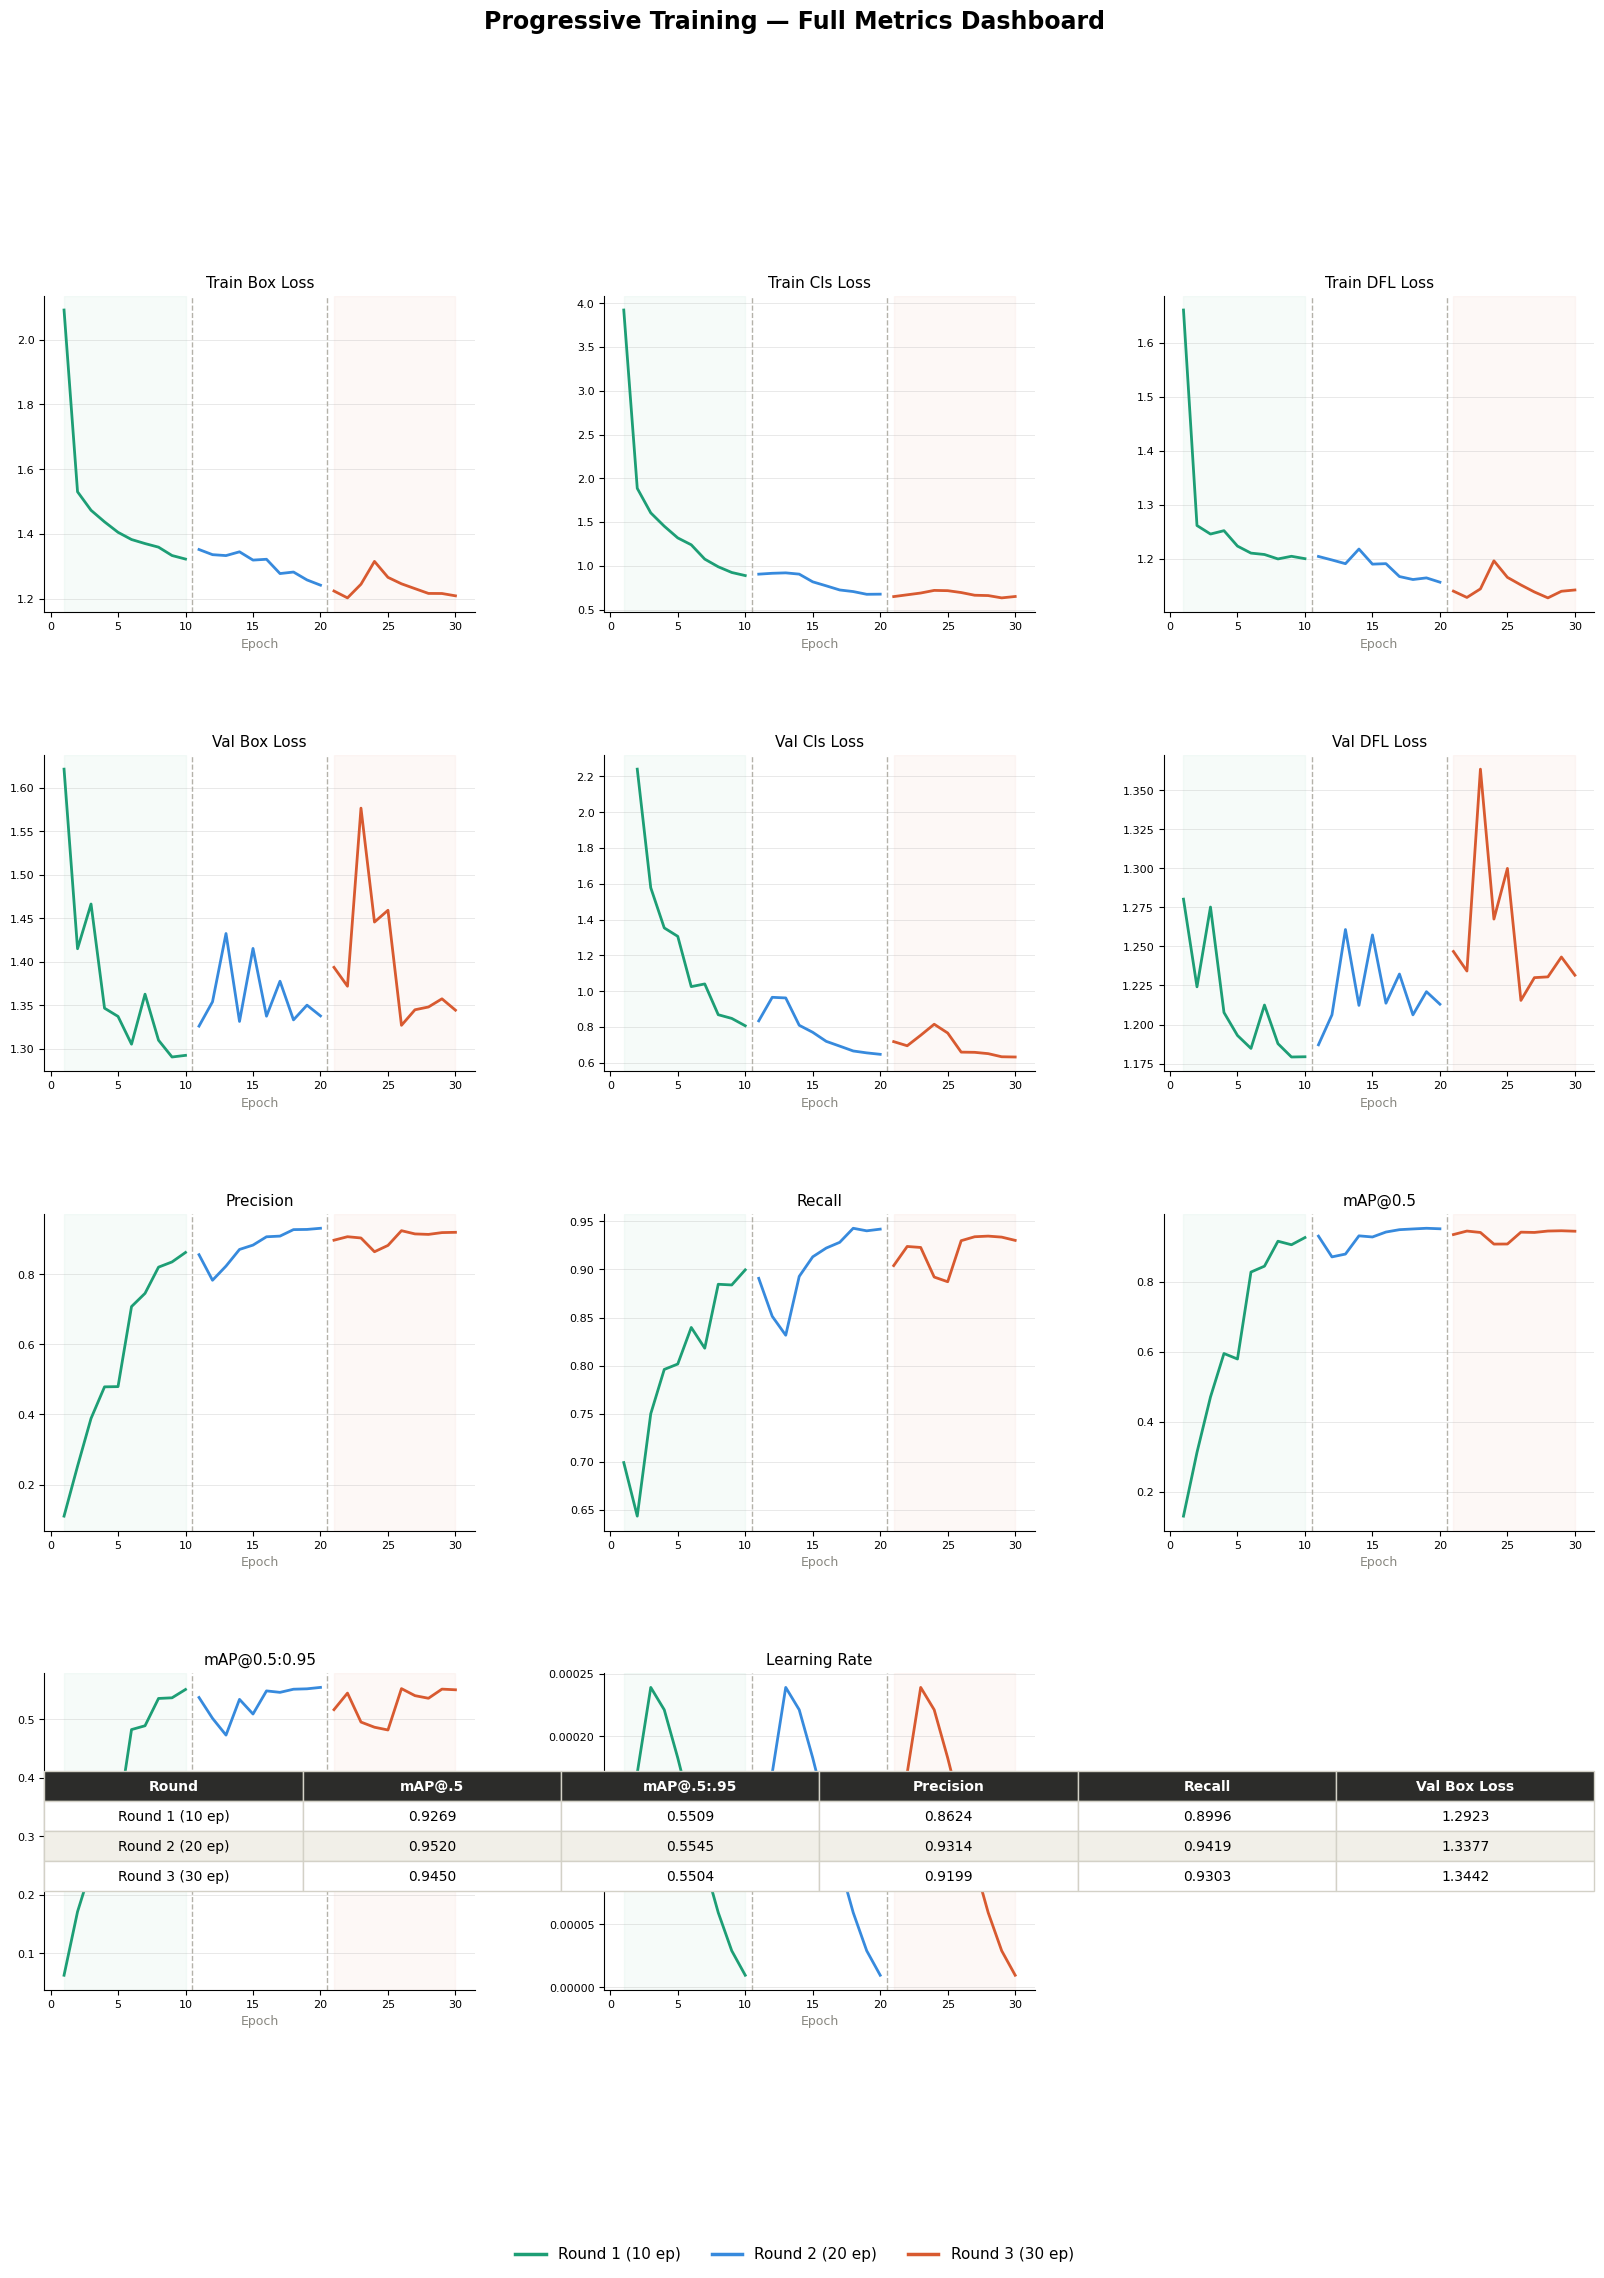

Saved → /kaggle/working/training_dashboard.png


In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import os

# ── load all rounds ──────────────────────────────────────
rounds = {
    "Round 1 (10 ep)": "/kaggle/working/panorai_runs/panorai_r1",
    "Round 2 (20 ep)": "/kaggle/working/panorai_runs/panorai_r2",
    "Round 3 (30 ep)": "/kaggle/working/panorai_runs/panorai_r3",
}

colors = {"Round 1 (10 ep)": "#1D9E75", "Round 2 (20 ep)": "#378ADD", "Round 3 (30 ep)": "#D85A30"}

dfs = {}
for label, path in rounds.items():
    csv_path = os.path.join(path, "results.csv")
    if os.path.exists(csv_path):
        df = pd.read_csv(csv_path)
        df.columns = df.columns.str.strip()
        dfs[label] = df

# ── metrics to plot ──────────────────────────────────────
metrics = [
    ("train/box_loss",      "Train Box Loss"),
    ("train/cls_loss",      "Train Cls Loss"),
    ("train/dfl_loss",      "Train DFL Loss"),
    ("val/box_loss",        "Val Box Loss"),
    ("val/cls_loss",        "Val Cls Loss"),
    ("val/dfl_loss",        "Val DFL Loss"),
    ("metrics/precision(B)","Precision"),
    ("metrics/recall(B)",   "Recall"),
    ("metrics/mAP50(B)",    "mAP@0.5"),
    ("metrics/mAP50-95(B)", "mAP@0.5:0.95"),
    ("lr/pg0",              "Learning Rate"),
]

# ── figure ───────────────────────────────────────────────
fig = plt.figure(figsize=(20, 22))
fig.suptitle("Progressive Training — Full Metrics Dashboard", fontsize=17, fontweight="bold", y=1.01)

gs = gridspec.GridSpec(4, 3, figure=fig, hspace=0.45, wspace=0.3)

for idx, (col, title) in enumerate(metrics):
    ax = fig.add_subplot(gs[idx // 3, idx % 3])
    epoch_offset = 0

    for label, df in dfs.items():
        if col not in df.columns:
            continue
        epochs = range(epoch_offset + 1, epoch_offset + len(df) + 1)
        ax.plot(epochs, df[col], color=colors[label], linewidth=2, label=label)
        epoch_offset += len(df)

    # shade round boundaries
    epoch_offset = 0
    shade = True
    for label, df in dfs.items():
        start = epoch_offset + 1
        end   = epoch_offset + len(df)
        if shade:
            ax.axvspan(start, end, alpha=0.04, color=colors[label])
        epoch_offset += len(df)
        shade = not shade

    ax.set_title(title, fontsize=11, fontweight="500")
    ax.set_xlabel("Epoch", fontsize=9, color="#888780")
    ax.tick_params(labelsize=8)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", linewidth=0.4, alpha=0.5)

    # round boundary vertical lines
    epoch_offset = 0
    for i, (label, df) in enumerate(dfs.items()):
        epoch_offset += len(df)
        if i < len(dfs) - 1:
            ax.axvline(epoch_offset + 0.5, color="#B4B2A9", linewidth=1, linestyle="--")

# ── shared legend ────────────────────────────────────────
handles = [plt.Line2D([0], [0], color=c, linewidth=2.5, label=l)
           for l, c in colors.items()]
fig.legend(handles=handles, loc="lower center", ncol=3,
           fontsize=11, frameon=False, bbox_to_anchor=(0.5, -0.02))

# ── summary table at the bottom ─────────────────────────
ax_table = fig.add_subplot(gs[3, :])
ax_table.axis("off")

table_data = []
for label, df in dfs.items():
    last = df.iloc[-1]
    table_data.append([
        label,
        f"{last.get('metrics/mAP50(B)', 0):.4f}",
        f"{last.get('metrics/mAP50-95(B)', 0):.4f}",
        f"{last.get('metrics/precision(B)', 0):.4f}",
        f"{last.get('metrics/recall(B)', 0):.4f}",
        f"{last.get('val/box_loss', 0):.4f}",
    ])

table = ax_table.table(
    cellText=table_data,
    colLabels=["Round", "mAP@.5", "mAP@.5:.95", "Precision", "Recall", "Val Box Loss"],
    loc="center",
    cellLoc="center",
)
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1, 1.8)

for (r, c), cell in table.get_celld().items():
    cell.set_edgecolor("#D3D1C7")
    if r == 0:
        cell.set_facecolor("#2C2C2A")
        cell.set_text_props(color="white", fontweight="bold")
    elif r % 2 == 0:
        cell.set_facecolor("#F1EFE8")
    else:
        cell.set_facecolor("white")

plt.savefig("/kaggle/working/training_dashboard.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved → /kaggle/working/training_dashboard.png")

# Cross validation


In [3]:
# ════════════════════════════════════════════════════════
# 1. Install
# ════════════════════════════════════════════════════════
!pip install -q ultralytics scikit-learn


# ════════════════════════════════════════════════════════
# 2. Imports
# ════════════════════════════════════════════════════════
import os
import json
import glob
import random
import cv2
import numpy as np

from pathlib import Path
from sklearn.model_selection import KFold
from ultralytics import YOLO


# ════════════════════════════════════════════════════════
# 3. Paths
# ════════════════════════════════════════════════════════
JSON_PATH = "/root/.cache/huggingface/hub/datasets--ibrahimhamamci--DENTEX/snapshots/7b27ccc8e342dcb774f69adc6ca5e6c09fefce93/DENTEX/training_data/training_data/quadrant_enumeration/train_quadrant_enumeration.json"

IMG_DIR = "/root/.cache/huggingface/hub/datasets--ibrahimhamamci--DENTEX/snapshots/7b27ccc8e342dcb774f69adc6ca5e6c09fefce93/DENTEX/training_data/training_data/quadrant_enumeration/xrays"

YOLO_ROOT = "/kaggle/working/dentex_yolo"

IMG_OUT   = f"{YOLO_ROOT}/images"
LABEL_OUT = f"{YOLO_ROOT}/labels"

os.makedirs(IMG_OUT, exist_ok=True)
os.makedirs(LABEL_OUT, exist_ok=True)


# ════════════════════════════════════════════════════════
# 4. Convert COCO → YOLO
# ════════════════════════════════════════════════════════
with open(JSON_PATH) as f:
    coco = json.load(f)

id_to_name = {
    img["id"]: img["file_name"]
    for img in coco["images"]
}

img_annotations = {}

for ann in coco["annotations"]:
    img_annotations.setdefault(ann["image_id"], []).append(ann)

print("Converting annotations...\n")

for img_id, anns in img_annotations.items():

    img_name = id_to_name[img_id]
    src_img  = os.path.join(IMG_DIR, img_name)

    if not os.path.exists(src_img):
        continue

    # copy image once
    dst_img = os.path.join(IMG_OUT, img_name)

    if not os.path.exists(dst_img):
        import shutil
        shutil.copy(src_img, dst_img)

    img = cv2.imread(src_img)
    h, w = img.shape[:2]

    yolo_lines = []

    for ann in anns:

        # 32 classes
        cls = ann["category_id_1"] * 8 + ann["category_id_2"]

        x, y, bw, bh = ann["bbox"]

        xc = (x + bw / 2) / w
        yc = (y + bh / 2) / h

        bw /= w
        bh /= h

        yolo_lines.append(
            f"{cls} {xc} {yc} {bw} {bh}"
        )

    label_path = os.path.join(
        LABEL_OUT,
        Path(img_name).stem + ".txt"
    )

    with open(label_path, "w") as f:
        f.write("\n".join(yolo_lines))

print("Conversion finished.")
print("Images:", len(os.listdir(IMG_OUT)))
print("Labels:", len(os.listdir(LABEL_OUT)))


# ════════════════════════════════════════════════════════
# 5. Prepare K-Fold splits (NO IMAGE COPYING)
# ════════════════════════════════════════════════════════
all_images = sorted(glob.glob(f"{IMG_OUT}/*.png"))

kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

fold_yaml_paths = []

CLASS_NAMES = [
    "11","12","13","14","15","16","17","18",
    "21","22","23","24","25","26","27","28",
    "31","32","33","34","35","36","37","38",
    "41","42","43","44","45","46","47","48"
]

for fold, (train_idx, val_idx) in enumerate(kf.split(all_images), 1):

    print(f"\nPreparing Fold {fold}")

    train_txt = f"/kaggle/working/train_fold{fold}.txt"
    val_txt   = f"/kaggle/working/val_fold{fold}.txt"

    # write train list
    with open(train_txt, "w") as f:
        for idx in train_idx:
            f.write(all_images[idx] + "\n")

    # write val list
    with open(val_txt, "w") as f:
        for idx in val_idx:
            f.write(all_images[idx] + "\n")

    # yaml
    yaml_path = f"/kaggle/working/fold{fold}.yaml"

    with open(yaml_path, "w") as f:

        f.write(f"""
path: {YOLO_ROOT}

train: {train_txt}
val: {val_txt}

names:
""")

        for i, name in enumerate(CLASS_NAMES):
            f.write(f"  {i}: '{name}'\n")

    fold_yaml_paths.append(yaml_path)

    print(f"Fold {fold} ready.")


# ════════════════════════════════════════════════════════
# 6. Train
# ════════════════════════════════════════════════════════
results = {
    "map50": [],
    "map": [],
    "precision": [],
    "recall": []
}

for fold, yaml_path in enumerate(fold_yaml_paths, 1):

    print("\n" + "=" * 60)
    print(f"TRAINING FOLD {fold}")
    print("=" * 60)

    model = YOLO("yolo11m.pt")

    model.train(
        data=yaml_path,
        epochs=30,
        imgsz=640,
        batch=16,
        device=0,

        lr0=0.01,
        cos_lr=True,

        patience=15,

        hsv_h=0.0,
        hsv_s=0.0,
        flipud=0.0,

        project="/kaggle/working/dentex_cv",
        name=f"fold{fold}"
    )

    # evaluate
    metrics = model.val(
        data=yaml_path,
        split="val",
        imgsz=640,
        device=0,
        verbose=False
    )

    map50 = metrics.box.map50
    map95 = metrics.box.map

    prec = metrics.box.mp
    rec  = metrics.box.mr

    results["map50"].append(map50)
    results["map"].append(map95)
    results["precision"].append(prec)
    results["recall"].append(rec)

    print(f"\nFold {fold} Results")
    print(f"mAP50      : {map50:.4f}")
    print(f"mAP50-95   : {map95:.4f}")
    print(f"Precision  : {prec:.4f}")
    print(f"Recall     : {rec:.4f}")


# ════════════════════════════════════════════════════════
# 7. Final Report
# ════════════════════════════════════════════════════════
print("\n" + "=" * 60)
print("FINAL CROSS-VALIDATION RESULTS")
print("=" * 60)

for metric, values in results.items():

    mean = np.mean(values)
    std  = np.std(values)

    print(f"{metric:<12} : {mean:.4f} ± {std:.4f}")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 21.3 MB/s eta 0:00:00a 0:00:01
Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Converting annotations...

Conversion finished.
Images: 634
Labels: 634

Preparing Fold 1
Fold 1 ready.

Preparing Fold 2
Fold 2 ready.

Preparing Fold 3
Fold 3 ready.

Preparing Fold 4
Fold 4 ready.

Preparing Fold 5
Fold 5 ready.

TRAINING FOLD 1
Ultralytics 8.4.47 🚀 Python-3.12.12 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr